# 02 - Filtragem Colaborativa com KNN

## Objetivo

Implementar e treinar o modelo KNN para filtragem colaborativa, com fundamentação matemática e justificativa da abordagem (user-based vs item-based).

## 1. Setup

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from surprise import Dataset, Reader, KNNWithMeans, accuracy, dump
from surprise.model_selection import train_test_split

## 2. Carregamento do dataset tratado

In [40]:
dataset_path = Path("../dataset/dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("src/dataset/dataset.csv")

df = pd.read_csv(dataset_path)

df.head()

,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,1,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,1,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,1,125.0,Espetáculo Musical


In [41]:
print("Dimensão do dataset:", df.shape)
print("Usuários únicos:", df["user_id"].nunique())
print("Itens únicos:", df["item_id"].nunique())
print("Ranking máximo:", df["ranking"].max())
print("Ranking mínimo:", df["ranking"].min())

Dimensão do dataset: (109916, 5)
Usuários únicos: 68499
Itens únicos: 449
Ranking máximo: 5
Ranking mínimo: 1


O dataset utilizado neste notebook foi gerado na etapa anterior de análise e preparação dos dados. Ele contém as colunas `user_id`, `item_id` e `ranking`, que representam respectivamente o usuário, o espetáculo e a força da interação entre eles.

Como a base original não possui avaliações explícitas, o `ranking` foi construído como feedback implícito, representando a quantidade de dias distintos em que o usuário interagiu com determinado espetáculo, limitado ao valor máximo de 5.

### 2.1. Contextualização do problema

O sistema de recomendação da Aventura tem como objetivo sugerir espetáculos culturais para usuários com base em seus padrões históricos de interação. Como a base original não possui avaliações explícitas, como notas dadas diretamente pelos usuários, foi necessário transformar as compras e interações em um sinal de feedback implícito.

Neste notebook, o `ranking` representa a intensidade da interação entre usuário e espetáculo, considerando a quantidade de dias distintos em que o usuário interagiu com determinado item, com limite máximo de 5. Dessa forma, o modelo não aprende preferências declaradas, mas sim padrões de comportamento observados na base.

A abordagem utilizada foi a filtragem colaborativa, pois ela permite gerar recomendações a partir das relações entre usuários e itens, sem depender diretamente de informações textuais ou categóricas dos espetáculos.

## 3. Fundamentação Teórica

### 3.1. Lógica do algoritmo

O KNN, ou *K-Nearest Neighbors*, é um algoritmo baseado em proximidade. Em sistemas de recomendação, ele é usado para encontrar usuários ou itens semelhantes a partir de uma matriz de interações.

No contexto deste projeto, a matriz usuário-item representa as interações entre usuários e espetáculos da Aventura. Cada linha representa um usuário, cada coluna representa um espetáculo e cada célula contém o valor de `ranking`, que indica a força da interação entre aquele usuário e aquele espetáculo.

A filtragem colaborativa com KNN funciona em três etapas principais:

1. **Cálculo de similaridade:** o algoritmo mede o quão parecidos são dois usuários ou dois itens com base nos padrões de interação.
2. **Seleção dos k vizinhos mais próximos:** após calcular as similaridades, são selecionados os `k` usuários ou itens mais semelhantes.
3. **Geração da recomendação:** o modelo utiliza os vizinhos mais próximos para estimar quais itens podem ser relevantes para o usuário.

Neste notebook, será utilizado o algoritmo `KNNWithMeans` da biblioteca `scikit-surprise`. Esse algoritmo aplica a lógica do KNN considerando a média das interações, permitindo prever o ranking estimado para pares usuário-item.

Essa abordagem é adequada para o artefato porque permite avaliar o modelo com métricas de regressão, como RMSE e MAE, além de possibilitar a geração de recomendações a partir das predições de ranking.

No contexto deste projeto, o KNN foi aplicado como uma técnica de filtragem colaborativa baseada em itens. Isso significa que o modelo não busca diretamente usuários parecidos, mas sim espetáculos com padrões de interação semelhantes. Assim, se um usuário demonstrou interesse por determinado espetáculo, o sistema pode estimar seu interesse por outros espetáculos consumidos por públicos parecidos.

Essa estratégia é útil para o caso da Aventura porque a base possui uma quantidade muito maior de usuários do que de itens. Comparar espetáculos entre si tende a ser mais eficiente e interpretável do que comparar todos os usuários da base.

---

### 3.2. Métricas de similaridade

Para que o KNN consiga encontrar os vizinhos mais próximos, é necessário definir uma métrica de similaridade. Essa métrica determina como o modelo calcula a proximidade entre dois usuários ou dois itens.

As principais métricas utilizadas em sistemas de recomendação são:

#### Similaridade do Cosseno

A similaridade do cosseno mede o ângulo entre dois vetores. No caso de recomendação item-based, cada item é representado por um vetor contendo as interações dos usuários com aquele item.

A fórmula é:

$$
\text{sim}(A,B) = \frac{\vec{A} \cdot \vec{B}}{||\vec{A}|| \cdot ||\vec{B}||}
$$

Onde:

- $\vec{A}$ representa o vetor de interações do item A;
- $\vec{B}$ representa o vetor de interações do item B;
- $\vec{A} \cdot \vec{B}$ representa o produto escalar entre os dois vetores;
- $||\vec{A}||$ representa a norma, ou magnitude, do vetor A;
- $||\vec{B}||$ representa a norma, ou magnitude, do vetor B.

Quanto mais próximo de 1 for o resultado, mais semelhantes são os itens. Quanto mais próximo de 0, menor é a similaridade entre eles.

Neste projeto, a similaridade do cosseno é adequada porque a matriz usuário-item é esparsa, ou seja, possui muitos valores iguais a 0. A métrica do cosseno permite comparar padrões de interação mesmo quando os usuários interagem com poucos itens do catálogo.

#### Correlação de Pearson

A correlação de Pearson mede a relação linear entre dois vetores, considerando a variação em torno da média. Ela é útil quando se deseja reduzir o impacto de usuários que tendem a avaliar tudo muito alto ou muito baixo.

A fórmula geral é:

$$
\text{sim}(u,v) = \frac{\sum_i (r_{ui} - \bar{r}_u)(r_{vi} - \bar{r}_v)}{\sqrt{\sum_i (r_{ui} - \bar{r}_u)^2} \sqrt{\sum_i (r_{vi} - \bar{r}_v)^2}}
$$

Onde:

- $r_{ui}$ é a interação do usuário $u$ com o item $i$;
- $r_{vi}$ é a interação do usuário $v$ com o item $i$;
- $\bar{r}_u$ é a média das interações do usuário $u$;
- $\bar{r}_v$ é a média das interações do usuário $v$.

Apesar de ser útil em bases com avaliações explícitas, como notas de 1 a 5, ela pode ser menos adequada neste caso, pois o `ranking` representa feedback implícito derivado de compras, e não avaliações subjetivas dadas pelos usuários.

#### MSD — Mean Squared Difference

A métrica MSD, ou diferença quadrática média, calcula a distância entre dois vetores com base nas diferenças entre suas interações.

A ideia é medir o quanto dois usuários ou itens se diferenciam em suas interações. Quanto menor a diferença quadrática média, mais semelhantes eles são.

A fórmula pode ser representada como:

$$
MSD(u,v) = \frac{1}{|I_{uv}|} \sum_{i \in I_{uv}} (r_{ui} - r_{vi})^2
$$

Onde:

- $I_{uv}$ representa o conjunto de itens em comum entre os usuários $u$ e $v$;
- $r_{ui}$ é a interação do usuário $u$ com o item $i$;
- $r_{vi}$ é a interação do usuário $v$ com o item $i$.

Essa métrica é simples, mas pode ser mais sensível à escala dos valores de interação.

---

### 3.3. Fórmula de predição

Em abordagens de KNN para recomendação, a predição de uma interação pode ser calculada a partir da média ponderada das interações dos vizinhos mais próximos.

Como neste notebook foi escolhida a abordagem **item-based**, a predição considera os itens mais semelhantes ao item que está sendo estimado. Uma formulação comum para esse tipo de abordagem é:

$$
\hat{r}_{ui} = \mu_i + \frac{\sum_{j \in N_k(i)} \text{sim}(i,j) \cdot (r_{uj} - \mu_j)}{\sum_{j \in N_k(i)} |\text{sim}(i,j)|}
$$

Onde:

- $\hat{r}_{ui}$ é a interação prevista do usuário $u$ com o espetáculo $i$;
- $\mu_i$ é a média das interações do espetáculo $i$;
- $N_k(i)$ representa o conjunto dos $k$ espetáculos mais semelhantes ao espetáculo $i$;
- $\text{sim}(i,j)$ é a similaridade entre o espetáculo $i$ e o espetáculo vizinho $j$;
- $r_{uj}$ é a interação real do usuário $u$ com o espetáculo vizinho $j$;
- $\mu_j$ é a média das interações do espetáculo vizinho $j$;
- o denominador $\sum_{j \in N_k(i)} |\text{sim}(i,j)|$ normaliza o cálculo pela soma das similaridades absolutas.

Neste notebook, foi utilizado o algoritmo `KNNWithMeans` da biblioteca `scikit-surprise`. Esse algoritmo aplica a lógica do KNN considerando a média das interações e os vizinhos mais próximos, permitindo prever o ranking estimado para pares usuário-item.

Essa abordagem é adequada para o artefato porque permite avaliar o modelo com métricas de regressão, como RMSE e MAE, além de possibilitar a geração de recomendações a partir das predições de ranking.

---

### 3.4. Justificativa da métrica escolhida

A métrica escolhida para este modelo foi a **similaridade do cosseno**.

Essa escolha se justifica porque:

- a matriz usuário-item possui alta esparsidade;
- o objetivo é comparar padrões de interação entre espetáculos;
- o cosseno é adequado para comparar vetores mesmo quando há muitos valores 0;
- a escala do `ranking` já foi limitada entre 1 e 5, reduzindo distorções;
- a abordagem facilita a identificação de itens semelhantes com base nos usuários que interagiram com eles.

Portanto, a similaridade do cosseno é uma escolha coerente para o primeiro modelo KNN de filtragem colaborativa aplicado ao sistema de recomendação da Aventura.

## 4. User-based vs Item-based

A filtragem colaborativa com KNN pode ser implementada de duas formas principais: baseada em usuários ou baseada em itens.

Na abordagem **user-based**, o modelo compara usuários entre si. A recomendação é feita a partir dos itens consumidos por usuários parecidos com o usuário alvo.

Na abordagem **item-based**, o modelo compara itens entre si. A recomendação é feita a partir de itens semelhantes àqueles que o usuário já consumiu.

Para este projeto, foi escolhida a abordagem **item-based**.

Essa decisão foi tomada porque o dataset possui uma quantidade muito maior de usuários do que de itens.Na etapa de preparação dos dados, a matriz usuário-item apresentou aproximadamente 68 mil usuários e algumas centenas de espetáculos. Dessa forma, é mais eficiente comparar os espetáculos entre si do que comparar todos os usuários.

Além disso, a abordagem item-based é mais interpretável para o contexto da Aventura, pois permite recomendar espetáculos semelhantes aos que o usuário já consumiu.

No `scikit-surprise`, a escolha entre abordagem baseada em usuários ou itens é definida por meio do parâmetro `user_based`.

Neste projeto, foi utilizada a abordagem item-based, configurada com `user_based=False`. Dessa forma, o modelo calcula similaridades entre espetáculos e utiliza esses padrões para prever o interesse dos usuários por itens ainda não consumidos.

## 5. Preparação dos dados para o Surprise

A biblioteca `scikit-surprise` recebe os dados no formato usuário, item e rating. Como a base tratada possui as colunas `user_id`, `item_id` e `ranking`, ela pode ser utilizada diretamente para a construção do modelo.

O `ranking` representa o feedback implícito do usuário com o espetáculo, construído a partir da quantidade de dias distintos de interação e limitado ao valor máximo de 5.

In [42]:
df_surprise = df[["user_id", "item_id", "ranking"]].copy()

reader = Reader(rating_scale=(1, 5))

data = Dataset.load_from_df(
    df_surprise[["user_id", "item_id", "ranking"]],
    reader
)

trainset, testset = train_test_split(
    data,
    test_size=0.2,
    random_state=42
)

print("Dados preparados para o Surprise.")
print("Tamanho do conjunto de teste:", len(testset))

Dados preparados para o Surprise.
Tamanho do conjunto de teste: 21984


## 6. Treinamento do modelo KNN com Surprise

Nesta etapa, foi utilizado o algoritmo `KNNWithMeans` da biblioteca `scikit-surprise`.

Esse modelo calcula a similaridade entre usuários ou itens e realiza a predição considerando a média dos ratings. Como a abordagem escolhida foi item-based, o parâmetro `user_based` foi definido como `False`.

A métrica escolhida foi a similaridade do cosseno, adequada para comparar padrões de interação em uma base esparsa. O valor de `k = 5` foi definido para considerar os cinco vizinhos mais próximos no cálculo da predição.

### 6.1. Escolha do KNNWithMeans

O algoritmo utilizado foi o `KNNWithMeans`, disponível na biblioteca `scikit-surprise`. Essa variação do KNN considera a média das interações no processo de predição, reduzindo distorções causadas por usuários ou itens que possuem padrões médios diferentes.

No contexto deste projeto, o modelo foi configurado como item-based por meio do parâmetro `user_based=False`. Dessa forma, a similaridade é calculada entre espetáculos, e a predição do ranking de um usuário para um item considera os itens mais semelhantes e as interações anteriores desse usuário com esses itens vizinhos.

Essa escolha torna o modelo mais coerente com o objetivo do sistema, que é recomendar espetáculos semelhantes aos interesses demonstrados pelo usuário.

### 6.2. Justificativa dos hiperparâmetros

O modelo foi configurado com os seguintes hiperparâmetros principais:

- `k = 5`: define a quantidade de vizinhos mais próximos considerados no cálculo da predição. Esse valor foi escolhido como configuração inicial simples e interpretável, permitindo considerar um conjunto reduzido de itens semelhantes sem tornar a recomendação excessivamente genérica.
- `sim_options["name"] = "cosine"`: define a similaridade do cosseno como métrica de comparação entre os itens. Essa métrica é adequada para bases esparsas, pois compara a direção dos vetores de interação e não apenas sua magnitude.
- `sim_options["user_based"] = False`: define a abordagem item-based, fazendo com que o modelo compare espetáculos entre si em vez de comparar usuários.

Esses hiperparâmetros foram definidos para criar um modelo inicial funcional, interpretável e compatível com a estrutura da base tratada.

In [43]:
sim_options = {
    "name": "cosine",
    "user_based": False
}

modelo_avaliacao = KNNWithMeans(
    k=5,
    sim_options=sim_options,
    verbose=True
)

modelo_avaliacao.fit(trainset)

print("Modelo de avaliação KNNWithMeans treinado com sucesso.")

Computing the cosine similarity matrix...
Done computing similarity matrix.
Modelo de avaliação KNNWithMeans treinado com sucesso.


## 7. Avaliação do modelo KNN

Após o treinamento, o modelo foi avaliado no conjunto de teste utilizando RMSE e MAE.

O RMSE mede a raiz do erro quadrático médio, penalizando erros maiores com mais intensidade. Já o MAE mede o erro absoluto médio entre o ranking real e o ranking previsto.

Essas métricas permitem avaliar o desempenho do modelo como uma tarefa de predição de ranking.

In [44]:
predictions_knn = modelo_avaliacao.test(testset)

rmse_knn = accuracy.rmse(predictions_knn)
mae_knn = accuracy.mae(predictions_knn)

RMSE: 0.3402
MAE:  0.1366


In [45]:
resultados_knn = pd.DataFrame({
    "modelo": ["KNNWithMeans item-based"],
    "RMSE": [rmse_knn],
    "MAE": [mae_knn]
})

resultados_knn

,modelo,RMSE,MAE
0,KNNWithMeans item-based,0.340209,0.136632


### Diagnóstico visual dos erros

Além de RMSE e MAE, analisamos a distribuição dos erros e a relação entre ranking real e ranking predito. Esses gráficos ajudam a identificar se o modelo possui tendência sistemática de superestimar ou subestimar os rankings e se as predições ficam excessivamente concentradas em torno da média.

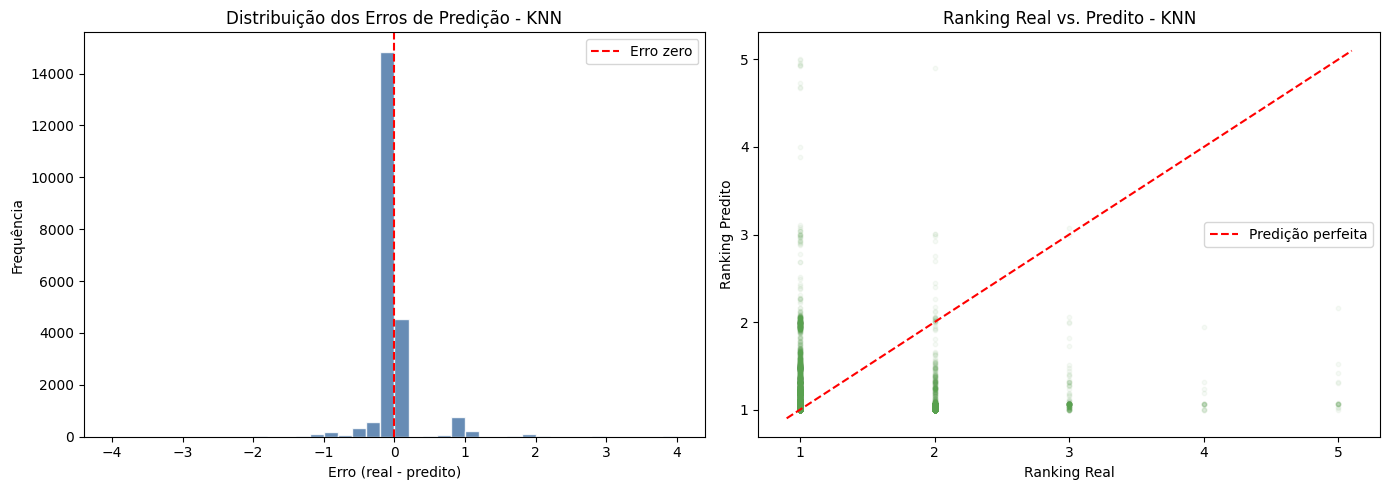

Média do erro  : -0.0119
Desvio padrão  : 0.3400


In [46]:
erros_knn = [pred.r_ui - pred.est for pred in predictions_knn]
reais_knn = [pred.r_ui for pred in predictions_knn]
preditos_knn = [pred.est for pred in predictions_knn]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(erros_knn, bins=40, color="#4C78A8", edgecolor="white", alpha=0.85)
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Erro zero")
axes[0].set_title("Distribuição dos Erros de Predição - KNN")
axes[0].set_xlabel("Erro (real - predito)")
axes[0].set_ylabel("Frequência")
axes[0].legend()

axes[1].scatter(reais_knn, preditos_knn, alpha=0.05, s=10, color="#59A14F")
lim = (min(min(reais_knn), min(preditos_knn)) - 0.1, max(max(reais_knn), max(preditos_knn)) + 0.1)
axes[1].plot(lim, lim, "r--", linewidth=1.5, label="Predição perfeita")
axes[1].set_title("Ranking Real vs. Predito - KNN")
axes[1].set_xlabel("Ranking Real")
axes[1].set_ylabel("Ranking Predito")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Média do erro  : {np.mean(erros_knn):.4f}")
print(f"Desvio padrão  : {np.std(erros_knn):.4f}")

### Treinamento do modelo final

As métricas acima foram calculadas com um modelo treinado apenas no conjunto de treino (`trainset`) e avaliado no conjunto de teste (`testset`). Esse modelo é útil para estimar o erro de generalização, mas não é o melhor candidato para ser salvo e utilizado em inferência.

Após a avaliação, treinamos um novo modelo KNN com a mesma configuração, agora usando `data.build_full_trainset()`, ou seja, 100% das interações disponíveis. Esse `modelo_knn_final` é o modelo destinado à geração de recomendações e à exportação para uso futuro.

In [47]:
full_trainset = data.build_full_trainset()

modelo_knn_final = KNNWithMeans(
    k=5,
    sim_options=sim_options,
    verbose=True
)

modelo_knn_final.fit(full_trainset)

print("Modelo final KNNWithMeans treinado com 100% dos dados.")

Computing the cosine similarity matrix...
Done computing similarity matrix.
Modelo final KNNWithMeans treinado com 100% dos dados.


### Interpretação das métricas

O modelo KNN item-based com `KNNWithMeans` obteve RMSE de **0.3402** e MAE de **0.1366** no conjunto de teste.

O RMSE indica a raiz do erro quadrático médio entre o ranking real e o ranking previsto. Já o MAE representa o erro médio absoluto entre as previsões e os valores reais.

Apesar de os valores indicarem que o modelo consegue gerar predições próximas dentro da escala de 1 a 5, a interpretação dessas métricas deve considerar a natureza da base. O `ranking` utilizado neste projeto representa feedback implícito, construído a partir de interações, e não avaliações explícitas de satisfação dos usuários.

Além disso, a base possui forte concentração de interações com ranking igual a 1. Por isso, RMSE e MAE podem não capturar completamente a qualidade das recomendações geradas. A comparação final com o modelo SVD/Funk SVD e com métricas complementares será importante para avaliar melhor o desempenho do sistema de recomendação.

## 8. Função de recomendação para usuário

A função de recomendação utiliza o modelo treinado para prever o ranking estimado de itens ainda não consumidos por um usuário.

A lógica da função é:

1. identificar os itens já consumidos pelo usuário;
2. listar os itens ainda não consumidos;
3. prever o ranking estimado para cada item não consumido;
4. ordenar os itens pelo maior ranking estimado;
5. retornar os principais itens recomendados.

Essa função representa a etapa de inferência do modelo KNN. Em vez de apenas avaliar o erro de predição, ela utiliza o modelo treinado para gerar recomendações práticas para um usuário específico. Assim, o modelo deixa de ser apenas uma ferramenta de avaliação e passa a ser utilizado como mecanismo de recomendação top-N.

In [48]:
def recomendar_para_usuario_surprise(modelo, df, user_id, top_n=5):
    """
    Gera recomendações para um usuário usando um modelo KNN treinado com scikit-surprise.

    A função identifica os itens já consumidos pelo usuário, prevê o ranking
    estimado para os itens ainda não consumidos e retorna os itens com maior
    potencial de interesse.

    Parâmetros:
        modelo: modelo treinado do scikit-surprise.
        df: DataFrame contendo as colunas user_id, item_id e ranking.
        user_id: identificador do usuário alvo.
        top_n: quantidade de recomendações desejadas.

    Retorno:
        DataFrame com os itens recomendados e seus rankings estimados.
    """
    if user_id not in df["user_id"].unique():
        raise ValueError(f"O usuário '{user_id}' não foi encontrado na base.")

    todos_itens = df["item_id"].unique()

    itens_consumidos = df[df["user_id"] == user_id]["item_id"].unique()

    itens_nao_consumidos = [
        item for item in todos_itens
        if item not in itens_consumidos
    ]

    predicoes = []

    for item in itens_nao_consumidos:
        pred = modelo.predict(user_id, item)

        predicoes.append({
            "user_id": user_id,
            "item_id": item,
            "ranking_estimado": pred.est
        })

    recomendacoes = (
        pd.DataFrame(predicoes)
        .sort_values("ranking_estimado", ascending=False)
        .head(top_n)
    )

    return recomendacoes

## 9. Teste com usuário de exemplo

Para validar a função de recomendação, foi selecionado um usuário com quantidade moderada de interações na base. Usuários com poucas interações podem gerar recomendações pouco informativas, enquanto usuários extremamente ativos podem representar comportamentos atípicos.

Por isso, foi escolhido um usuário com volume intermediário de consumo, permitindo observar melhor o funcionamento do modelo em um perfil mais representativo.

In [49]:
usuarios_ativos = (
    df.groupby("user_id")
    .size()
    .sort_values(ascending=False)
)

usuarios_validos = usuarios_ativos[
    (usuarios_ativos >= 5) & (usuarios_ativos <= 30)
]

usuario_exemplo = usuarios_validos.index[0]

print("Usuário selecionado:", usuario_exemplo)
print("Quantidade de itens consumidos:", usuarios_validos.loc[usuario_exemplo])

Usuário selecionado: 64907
Quantidade de itens consumidos: 19


In [50]:
print("\nItens já consumidos pelo usuário:")
display(
    df[df["user_id"] == usuario_exemplo][["item_id", "ranking"]]
    .sort_values("ranking", ascending=False)
    .head(10)
)


Itens já consumidos pelo usuário:


,item_id,ranking
104280,NOEL ROSA: COISA NOSSA,3
104269,(1) LONGA JORNADA NOITE ADENTRO,1
104279,MUSICAL HAIRSPRAY,1
104286,UM FILME ARGENTINO - COM LETÍCIA COLIN E MICHE...,1
104285,SRA. KLEIN,1
104284,SINATRA BY KRAMARENCO,1
104283,SILVIO SANTOS VEM AÍ,1
104282,QUANDO EU FOR MÃE QUERO AMAR DESSE JEITO – COM...,1
104281,PRIMA FACIE COM DÉBORA FALABELLA,1
104278,MUSEU NACIONAL [TODAS AS VOZES DO FOGO],1


In [51]:
print("\nRecomendações geradas:")

recomendar_para_usuario_surprise(
    modelo=modelo_knn_final,
    df=df,
    user_id=usuario_exemplo,
    top_n=5
)


Recomendações geradas:


,user_id,item_id,ranking_estimado
423,64907,PRÊMIO SIM A IGUALDADE RACIAL 2023,2.393194
4,64907,FIBRA – FESTIVAL INSTRUMENTAL BRASIL: BEBÊ KRA...,1.684923
58,64907,CAINÃ CAVALCANTE – SINAL DOS TEMPOS / PARTICIP...,1.609854
277,64907,TOM KARABACHIAN NO SOMAMOS FESTIVAL,1.597304
354,64907,OS ALACANTOS - FEITIÇO DE ÁQUILA,1.560262


## 10. Limitações do modelo KNN

Apesar de o modelo KNN item-based estar funcional, algumas limitações devem ser consideradas.

A primeira limitação está relacionada à esparsidade da base. Como muitos usuários interagem com poucos espetáculos, a matriz usuário-item possui muitos valores ausentes. Isso pode dificultar o cálculo de similaridades confiáveis entre itens com poucas interações.

Outra limitação é o possível viés de popularidade. Espetáculos com maior volume de interações tendem a aparecer com mais frequência nos padrões de consumo, podendo influenciar as recomendações e reduzir a diversidade dos itens sugeridos.

Também existe o problema de cold-start. Novos usuários com poucas interações e novos espetáculos sem histórico suficiente são mais difíceis de recomendar, pois o KNN depende diretamente de padrões observados anteriormente.

Além disso, como o ranking utilizado é um feedback implícito construído a partir de compras e interações, ele não representa uma avaliação explícita de satisfação do usuário. Portanto, métricas como RMSE e MAE devem ser interpretadas com cuidado, especialmente em uma base desbalanceada com grande concentração de rankings iguais a 1.

Por esses motivos, a comparação com o modelo SVD/Funk SVD será importante para verificar se uma abordagem baseada em fatores latentes consegue capturar padrões mais profundos de preferência.

## 11. Resultados do modelo KNN

Neste notebook, foi implementado um modelo de recomendação com KNN utilizando a biblioteca `scikit-surprise`.

A abordagem escolhida foi item-based, pois a base possui maior quantidade de usuários do que itens, tornando mais viável comparar espetáculos entre si. O modelo foi treinado com `KNNWithMeans`, similaridade do cosseno e `k = 5`.

O modelo foi capaz de prever rankings para pares usuário-item, gerar recomendações para usuários reais e ser avaliado com RMSE e MAE. Essa implementação atende à etapa de filtragem colaborativa com KNN e servirá como base para comparação futura com modelos de fatoração de matrizes, como SVD ou Funk SVD.

## 12. Exportação do modelo

O modelo KNN final, treinado com 100% das interações disponíveis, foi salvo utilizando o método `dump` da biblioteca `scikit-surprise`. Essa etapa permite reutilizar o modelo treinado em etapas futuras de inferência ou comparação com outros modelos.

O arquivo foi salvo com extensão `.pkl`, pois o método `dump` utiliza serialização compatível com pickle. Dessa forma, o carregamento futuro do modelo deve ser feito com o próprio `dump.load` do `scikit-surprise`, e não com `joblib.load`.

In [52]:

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

dump.dump(
    str(model_dir / "knn_surprise_model.pkl"),
    algo=modelo_knn_final
)

print("Modelo KNN Surprise salvo em:", model_dir)

Modelo KNN Surprise salvo em: ..\models


## 13. Conclusões

Neste notebook, foi implementado um modelo de recomendação utilizando filtragem colaborativa baseada em itens com KNN.

A abordagem item-based foi escolhida porque a base possui uma quantidade muito maior de usuários do que de itens, tornando mais viável comparar espetáculos entre si. Além disso, essa abordagem é mais interpretável para o contexto da Aventura, pois permite recomendar espetáculos semelhantes aos que o usuário já consumiu.

O modelo foi implementado com `KNNWithMeans` da biblioteca `scikit-surprise`, utilizando similaridade do cosseno e `k = 5`. Essa configuração permitiu prever rankings estimados para itens ainda não consumidos e gerar recomendações para usuários reais da base.

A avaliação inicial foi realizada com RMSE e MAE, permitindo medir o erro entre os rankings reais e os rankings previstos. No entanto, como a base possui feedback implícito e forte concentração de interações com ranking igual a 1, essas métricas devem ser analisadas com cautela.

A função de recomendação criada utiliza o modelo treinado para estimar o interesse do usuário em espetáculos ainda não consumidos, retornando os itens com maior ranking previsto.

Conclui-se que o KNN cumpre a etapa de implementação da filtragem colaborativa e fornece uma abordagem funcional, simples e interpretável para recomendação. Entretanto, suas limitações relacionadas à esparsidade, popularidade e cold-start justificam a comparação com o modelo SVD/Funk SVD, que pode capturar fatores latentes mais profundos da matriz usuário-item.

Dessa forma, a escolha do melhor modelo será realizada posteriormente por meio da comparação entre KNN e SVD/Funk SVD, considerando RMSE, MAE e métricas complementares de classificação e recomendação, como precisão, recall, F1-score e acurácia.